# 07. Relaxation

- Teaches the calculation that turns a placed structure into a result: let the atoms move downhill until the forces on them are small, and report the energy of the geometry the model itself chose
- The first module that drives `mliprun` from the terminal instead of from Python: one command per relaxation, and a folder of output files to read afterwards
- The first module in which a calculation does not converge, which is what canon `K1` is about and what the `converged` column of every table below is for
- Ten relaxations run here, through seven commands, and one of the ten does not converge
- Before you start: modules 00 to 06 finished, the `mlip-mace` environment active, and Jupyter Lab running
    - The kernel shown at the top right of this notebook is "Python 3 (ipykernel)", the Python of that environment
    - The model weights sit in `~/.cache/mace/` from step 10 of module 00, so nothing is downloaded here
- The model is `mace` (MACE-MP-0) in every command, and the structures are the clean Pt(1 1 1) slab of module 04 and the four O sites of module 05, the same ones module 06 took single points of
- After this you can run a relaxation from the terminal, read every file it leaves behind, say whether it converged and on what evidence, relax a folder of structures in one command, check a relaxed structure against the site name on its folder, and assemble an adsorption energy whose every term was relaxed at the same settings

### Before you run this for a project

- The values in this notebook are teaching values, chosen so it runs on a laptop in minutes
- In a project, the items below are decided by your supervisor and written in the project's `CANON.md`; they are never taken from a tool default
    - `C1` MLIP model and head: this notebook uses `mace` (MACE-MP-0); the project may use another
    - `C2` force convergence `fmax`: this notebook uses 0.05 eV/Å, with the `bfgs` optimizer and a ceiling of 200 steps; the target, the optimizer and the ceiling are three separate decisions and a project records all three
    - `C4` one `fmax` for a whole energy diagram: every structure whose energies are subtracted from each other is relaxed to the same target with the same optimizer, references included
    - `K1` `converged` is a label the tool writes, never an assumption you may make: a run that stopped at the step ceiling is reported here with `converged` false, and its energy is not a result
- If a value is not recorded, ask before running; the tool will not stop you

## 0. The setup cell

- Run this cell first, every time you open the notebook
- This notebook writes files, where module 06 wrote none
    - `mliprun` relaxes a structure that it reads from a file, and it writes its outputs into the folder that file sits in
    - So `work/` fills up as you go: one folder per relaxation, each holding its input and its outputs
- `sys.path.insert(0, str(Path("../../scripts").resolve()))` puts the repository's `scripts` folder at the front of the list of folders Python searches, as in modules 05 and 06, so `from onboarding_structures import ...` works
- `sys`, `pathlib`, `json`, `subprocess` and `time` all come with Python
    - `subprocess` runs another program from inside Python, which is how a terminal command is run from a notebook cell
    - `json` reads `mliprun_run.json`, the run record every relaxation writes
- `numpy` is imported under the short name `np` and `pandas` under `pd`, as in modules 01 to 06
- `write` and `read` come from `ase.io`, as in module 05: `write` saves a structure to a file and `read` loads one back
- `MLIP = Path(sys.executable).parent / "mlip"` is the `mlip` command of this environment
    - `sys.executable` is the full path of the Python that runs this notebook, and the `mlip` program of the same environment sits next to it
    - Calling it by that path means the notebook always uses the `mlip` of this kernel, whatever environment your shell happens to have active
    - In the terminal you type `mlip` on its own, with the `mlip-mace` environment active, and that is what the command lines printed below show
- `run_mlip(arguments)` is the one function this notebook uses to run a command
    - It prints the command as you would type it, runs it, prints how long it took, and gives back the result
    - `capture_output=True, text=True` keeps what the command printed inside Python as text, instead of letting all of it land in the notebook, so each section can print the part of it that matters
    - `result.returncode` is 0 when the program itself ran; this function stops the notebook on anything else, after printing the end of the command's error output
    - A relaxation that does not converge is not a program failure, so the return code stays 0 in that case as well; the section on relaxing many structures is where you see that happen
- `shorten(text)` and `last_lines(text, n)` are about reading terminal output inside a notebook
    - The command prints full paths: the folder it wrote into, each file it wrote, and the weights file the model was read from
    - Those paths are different on every computer, so `shorten` replaces three folder names in the text: this notebook's own folder, which becomes nothing, the environment folder, which becomes `<environment>`, and your home folder, which becomes `~`
    - `last_lines(text, n)` keeps the last `n` lines that carry anything
    - Nothing else is changed; run the same command in a terminal and you see the same lines with the full paths in them
- `final_stage(folder)` reads the run record of one relaxation and returns its last stage, and the section on reading the outputs is where its contents are laid out
- `SITES` is the four sites of module 05, in the order every table below uses them

In [1]:
import json
import subprocess
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from ase.io import read, write

sys.path.insert(0, str(Path("../../scripts").resolve()))
from onboarding_structures import molecule_in_box, pt111_slab, pt111_with_adsorbate

WORK = Path("work")
WORK.mkdir(exist_ok=True)
SITES = ("ontop", "bridge", "fcc", "hcp")

MLIP = Path(sys.executable).parent / "mlip"
HERE = Path.cwd()
ENVIRONMENT = Path(sys.executable).parent.parent
HOME = Path.home()


def shorten(text):
    """Replace this computer's own folder names in a block of terminal output."""
    return (text.replace(str(HERE) + "/", "")
                .replace(str(ENVIRONMENT), "<environment>")
                .replace(str(HOME), "~"))


def last_lines(text, n):
    """The last n lines of a block of output that carry anything."""
    kept = [line for line in shorten(text).splitlines() if line.strip()]
    return "\n".join(kept[-n:])


def run_mlip(arguments):
    """Run one mlip command and return what subprocess.run gives back."""
    print("Command, as you would type it in the terminal")
    print(" ".join(["mlip"] + arguments))
    started = time.perf_counter()
    result = subprocess.run([str(MLIP)] + arguments, capture_output=True, text=True)
    print()
    print("Seconds the command took")
    print(round(time.perf_counter() - started, 1))
    if result.returncode != 0:
        print()
        print("The command failed, and this is the end of what it wrote to its error stream")
        print(last_lines(result.stderr, 15))
        raise SystemExit("mlip command failed")
    return result


def final_stage(folder):
    """The last stage of the run record mliprun wrote in that folder."""
    record = json.loads((Path(folder) / "mliprun_run.json").read_text())
    return record["stages"][-1]


print("Folder this notebook writes into")
print(WORK)
print("The mlip command of this environment was found")
print(MLIP.exists())
print("Sites this notebook relaxes an O atom on")
print(list(SITES))

Folder this notebook writes into
work
The mlip command of this environment was found
True
Sites this notebook relaxes an O atom on
['ontop', 'bridge', 'fcc', 'hcp']


## 1. What a relaxation does

- A relaxation moves the atoms of a structure downhill in energy until the forces on them are small enough to stop
    - The force on an atom is minus the slope of the energy against that atom's position, as module 06's section on energy and forces said, so a force is a direction in which that atom can still lower the energy
    - At a minimum every force is zero; a real relaxation never reaches exactly zero and stops at a chosen size instead
    - Atoms held by a constraint do not move: the bottom layer stays fixed, which leaves 18 of the clean slab's 27 atoms and 19 of each adsorbate structure's 28 atoms free
- An optimizer is the rule that decides, from the forces where the atoms are now, where to put them next
    - `bfgs` and `fire` are the two used here, and the section on optimizers compares them on the same structure
    - Each step needs the model's forces at one new geometry, which is why the number of steps is what a relaxation costs
- `--fmax` is the size the largest force on any free atom has to fall below, in eV/Å
    - 0.05 eV/Å is this notebook's teaching value, canon `C2`
    - A smaller `fmax` means a tighter structure and more steps; the section on convergence targets measures how many more, and how much the energy changes
- `--max-steps` is a ceiling on the number of steps, not a target
    - The run stops at whichever comes first: the force falling below `--fmax`, or the step count reaching the ceiling
    - Those two endings say completely different things, and the only thing that tells them apart is the `converged` label
- `converged` is a label the tool writes, canon `K1`
    - `converged` true means the force target was reached, and only then is the final energy the energy of a geometry this model chose
    - `converged` false means the run ran out of steps somewhere on the way down, and the final energy is the energy of wherever it happened to stop
    - The command ends normally either way, so nothing in your shell, your job script or your notebook will complain; you read the label, or you report a number that does not mean what you think it means
    - One relaxation in this notebook ends that way, and the section on relaxing many structures is where the label shows it

## 2. Run one relaxation from the command line

- The command reads a structure from a file, so the structure is written to a file first
    - `pt111_with_adsorbate("O", "fcc")` builds it, the one-line helper of module 05
    - `write(path, atoms, format="vasp", direct=True, sort=True)` saves it, the same call module 05's section on saving the structures used, so the file carries the fixed bottom layer as its `F F F` flags
    - `POSCAR` is VASP's name for a structure file, and `--input-name POSCAR` in the section on relaxing many structures is why this notebook uses that name rather than `something.vasp`
    - `sort=True` groups the atoms by species, which puts the single O first in the file; so the O is found by its symbol below and never by the index it had in memory, exactly as module 05 said
    - The file format has no way to record that the slab is not periodic along z, so what mliprun reads back is periodic in all three directions; module 04 built it with 10 Å of vacuum on each side, and the step 0 energy of the next section comes out as module 06's in-memory number to the decimals that module printed, which is how you know it did not matter here
- The command, as you would type it with the `mlip-mace` environment active:
    - `mlip optimize run --structure work/O_fcc/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200`
- Every value in it is named on purpose
    - `--mlip mace` names the model, canon `C1`; leave it out and mliprun picks one for you, which module 06's section on attaching a calculator is about
    - `--device cpu` runs the model on the processor, as module 06 did, so the command does the same thing on a laptop and on a cluster login node
    - `--fmax 0.05`, `--optimizer bfgs` and `--max-steps 200` happen to be this version's own defaults as well, and they are typed out anyway: a default is a decision somebody else made, and `C2` makes it yours
- What the command prints, from the top
    - The file it read, with the number of atoms and the formula, which is the first thing to check
    - `🧠 Using MLIP: mace`, printed because the command named the model; leave `--mlip` out and that line reads `🧠 Auto-detected MLIP:` followed by whatever it picked, and this course never lets it get there
    - Three lines the model itself prints while it loads, the ones module 06 kept out of its own output by sending them to a buffer: the acceleration it could not find, the weights file it read, and the warning that it runs in single precision
    - The settings it is about to use, which is where you check that `--fmax` arrived as you meant it
    - The folder it wrote into, and a list of the files it wrote
- That list names six files and the folder holds seven
    - The seventh is `mliprun_run.json`, the run record, written by a layer underneath the command that does not add itself to the list
    - The next section opens all of them
- The paths in that output are full paths on your own computer, and the cell prints them with the local folder names replaced, as the setup cell describes

In [2]:
site_dir = WORK / "O_fcc"
site_dir.mkdir(parents=True, exist_ok=True)
write(site_dir / "POSCAR", pt111_with_adsorbate("O", "fcc"),
      format="vasp", direct=True, sort=True)

print("Structure file written")
print(site_dir / "POSCAR")

print()
result = run_mlip(["optimize", "run",
                   "--structure", "work/O_fcc/POSCAR",
                   "--mlip", "mace",
                   "--device", "cpu",
                   "--fmax", "0.05",
                   "--optimizer", "bfgs",
                   "--max-steps", "200"])

print()
print("Everything the command printed, with the local folder names replaced")
print(last_lines(result.stdout, 20))

Structure file written
work/O_fcc/POSCAR

Command, as you would type it in the terminal
mlip optimize run --structure work/O_fcc/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200



Seconds the command took
11.5

Everything the command printed, with the local folder names replaced
📂 Loaded structure: POSCAR
   Atoms: 28, Formula: OPt27
🧠 Using MLIP: mace
⚙️  Attaching mace calculator (device=cpu)...
cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Using Materials Project MACE for MACECalculator with ~/.cache/mace/20231203mace128L1_epoch199model
Using float32 for MACECalculator, which is faster but less accurate. Recommended for MD. Use float64 for geometry optimization.
🔧 Optimizer: BFGS
   fmax = 0.05 eV/Å
   max_steps = 200
   Output dir: work/O_fcc
✅ Optimization complete. Output files:
   📄 work/O_fcc/opt.traj
   📄 work/O_fcc/opt.log
   📄 work/O_fcc/opt_convergence.csv
   📄 work/O_fcc/opt_final.vasp
   📄 work/O_fcc/CONTCAR
   📄 work/O_fcc/opt_params.txt


## 3. Read the outputs

- A relaxation leaves a folder, not a number, and each file in it answers a different question
    - `opt.log` is the optimizer's own step-by-step table, the one you would watch scroll past in a terminal
    - `opt_convergence.csv` is that table as data: one row per step, with the energy and the largest force
    - `opt.traj` holds every geometry the run passed through, which module 09 reads
    - `opt_final.vasp` is the geometry the run ended on, and `CONTCAR` is the same structure under the name a VASP run would give it
    - `opt_params.txt` is the settings as plain text, for reading without a script
    - `mliprun_run.json` is the run record: the settings, the versions, the timing and the outcome, in a form a script can read
- Three of those names come out of one option, and knowing which saves an hour one day
    - `opt.log`, `opt_convergence.csv` and `opt_final.vasp` are all built from `--logfile`, whose default is `opt.log`: the stem `opt` is what the other two are made from, so `--logfile run1.log` turns them into `run1_convergence.csv` and `run1_final.vasp`
    - `opt.traj` comes from a separate option, `--trajectory`, whose default is `opt.traj`
    - `CONTCAR`, `opt_params.txt` and `mliprun_run.json` are fixed names
    - This notebook passes neither option, so every folder below holds exactly these names
- `--plot` would add one more file, `opt_convergence.png`, a figure of the same two columns as the next subsection draws
    - It is off by default, and this notebook leaves it off and draws its own figure from the `.csv`, which is always written
- The run record has no top-level `converged` field, and looking for one is the first mistake everybody makes
    - Its top level holds `status`, `parameters`, `provenance` and a list of `stages`
    - One relaxation is one stage, so the outcome is in the last stage: its `status` is the word `converged` or `not_converged`, its `steps` is how many steps were taken, and its `results` holds `converged` as true or false together with the final energy and the final force
    - `final_stage(folder)` of the setup cell is that lookup, and the cell below prints all three places the outcome appears
- pandas in the cell below
    - `pd.read_csv(path)` reads a comma-separated file into a table
    - `len(df)` is the number of rows in it
    - `df["energy(eV)"].iloc[-1]` is the last value of one column, `iloc` meaning by position; `.iloc[0]` is the first
    - `df.head(3).to_string(index=False)` prints the first three rows as an aligned table without row numbers, as in modules 01 to 06
    - The column is spelled `fmax(eV/A)` in the file, with a plain `A` for the ångström, and a column name has to be typed as it is written
- In the printed output:
    - The folder holds eight files: the `POSCAR` you wrote and the seven the run left
    - The table has one more row than the record's step count, because the first row is step 0, the structure exactly as you handed it over
    - Step 0's energy is therefore a single point of the starting geometry, and it is module 06's `fcc` number to the three decimals that module printed: a relaxation contains the single point it started from
    - The last row of the table and the record's `results` carry the same energy and the same force, which is worth checking once so that you know it

In [3]:
curve = pd.read_csv(site_dir / "opt_convergence.csv")
stage = final_stage(site_dir)
record = json.loads((site_dir / "mliprun_run.json").read_text())

print("Files in work/O_fcc after the run")
print(sorted(path.name for path in site_dir.iterdir()))

print()
print("First three rows of opt_convergence.csv")
print(curve.head(3).to_string(index=False))

print()
print("Rows in opt_convergence.csv")
print(len(curve))
print("Steps the run record reports")
print(stage["steps"])

print()
print("Energy at step 0, a single point of the starting geometry (eV)")
print(round(float(curve["energy(eV)"].iloc[0]), 3))
print("Energy at the last step (eV)")
print(round(float(curve["energy(eV)"].iloc[-1]), 3))
print("Largest force at the last step (eV/Å)")
print(round(float(curve["fmax(eV/A)"].iloc[-1]), 4))

print()
print("Status at the top of the run record")
print(record["status"])
print("Status of the last stage")
print(stage["status"])
print("converged, from the last stage's results")
print(stage["results"]["converged"])
print("Final energy from the last stage's results (eV)")
print(round(stage["results"]["final_energy_eV"], 3))
print("Final largest force from the last stage's results (eV/Å)")
print(round(stage["results"]["final_fmax_eV_per_A"], 4))

Files in work/O_fcc after the run
['CONTCAR', 'POSCAR', 'mliprun_run.json', 'opt.log', 'opt.traj', 'opt_convergence.csv', 'opt_final.vasp', 'opt_params.txt']

First three rows of opt_convergence.csv
 step  energy(eV)  fmax(eV/A)
    0 -158.197083    1.782567
    1 -158.314560    1.062311
    2 -158.430588    0.633186

Rows in opt_convergence.csv
17
Steps the run record reports
16

Energy at step 0, a single point of the starting geometry (eV)
-158.197
Energy at the last step (eV)
-158.819
Largest force at the last step (eV/Å)
0.0442

Status at the top of the run record
converged
Status of the last stage
converged
converged, from the last stage's results
True
Final energy from the last stage's results (eV)
-158.819
Final largest force from the last stage's results (eV/Å)
0.0442


### 3a. The convergence curves

- Two panels against the optimizer step: the energy on the left, the largest force on the right
- The force panel has a logarithmic y axis: `fmax` falls from 1.78 eV/Å at step 0 to 0.044 eV/Å at the end, a factor of forty, and on a linear axis the target and the last few steps would all be crowded into the bottom three per cent of the panel
- The dashed line is the `--fmax` target, and the run stops at the first step under it
- Module 01's section on one plot drew this same pair of columns from a made-up table, and the difference between that one and this one is worth looking at
    - The made-up force fell smoothly; this one rises at five of the sixteen steps
    - A step that raises the force is normal for `bfgs`: it works from an approximation to how the energy curves, and it improves that approximation from every step it takes, so an early step can be aimed by a picture that is still wrong
    - What has to fall is the energy, and the left panel shows it falling at every step
- `matplotlib.pyplot` is imported here under the short name `plt`, as in modules 01, 04 and 05
- `df["fmax(eV/A)"].diff()` is the change in a column from one row to the next, and `(... > 0).sum()` counts the rows where that change is positive
- In the plot:
    - The energy drops fast over the first ten steps and then flattens on the scale of the panel
    - The force is what decides when to stop, and it is still bouncing at the point where the energy has visibly stopped changing
    - So a relaxation is long in its tail, and most of its steps buy force rather than energy

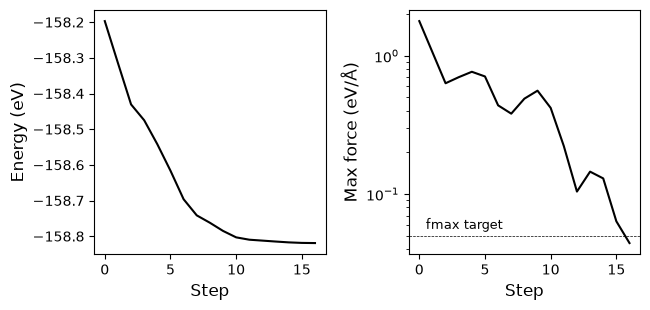

Steps in the run
16
Steps where the largest force rose instead of falling
5


In [4]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(6.6, 3.2))

axes[0].plot(curve["step"], curve["energy(eV)"], linestyle="-", color="k")
axes[0].set_xlabel("Step", fontsize=12)
axes[0].set_ylabel("Energy (eV)", fontsize=12)

axes[1].plot(curve["step"], curve["fmax(eV/A)"], linestyle="-", color="k")
axes[1].set_yscale("log")
axes[1].axhline(0.05, color="k", linestyle="--", linewidth=0.5)
axes[1].text(0.5, 0.056, "fmax target", fontsize=9)
axes[1].set_xlabel("Step", fontsize=12)
axes[1].set_ylabel("Max force (eV/Å)", fontsize=12)

fig.tight_layout()
plt.show()

print("Steps in the run")
print(int(curve["step"].iloc[-1]))
print("Steps where the largest force rose instead of falling")
print(int((curve["fmax(eV/A)"].diff() > 0).sum()))

### 3b. What moved

- `opt_final.vasp` read back and compared with the `POSCAR` you wrote is the whole answer to what the relaxation did
- `o_geometry(path)` measures where the O atom sits in one structure file, and it is used again in the section on the site `bfgs` could not finish
    - `symbols.index("O")` finds the O by its symbol, because `sort=True` moved it to the front of the file
    - `atoms.get_distances(i, indices, mic=True)` gives the distances in Å from one atom to every atom in a list, and `mic=True` measures across the periodic boundary when that is shorter, as module 05's section on the four sites used it
    - `np.sort(array)` puts those distances in increasing order, so the first is the nearest Pt and the third is the third nearest
    - `(distances < distances[0] + 0.1).sum()` counts how many Pt atoms sit within 0.1 Å of the nearest one, which is module 05's way of checking a site name against the geometry rather than trusting it
    - `array.mean()` averages an array, used on the z of the nine highest Pt atoms, which is the height of the top layer
    - `get_tags()` of module 04 would be the obvious way to find that layer, and it does not work here: the layer tags are not part of the file format, so a structure read back from a `POSCAR` carries none, and the top layer has to be found by its z
- `np.linalg.norm(vector)` is the length of a vector, used on the change in the O atom's x and y, which is how far it slid in the surface plane
- `pd.DataFrame(rows).to_string(index=False)` prints a list of dictionaries as an aligned table without row numbers, as in modules 01 to 06, and every table the notebook builds from a list of dictionaries from here on is printed that way
- In the printed output:
    - The O keeps three Pt neighbours, and the site is a three-fold hollow after the relaxation as it was before it
    - Those three move out from 2.062 Å to 2.113 Å, so this model wants the O a little further from the surface than module 05's starting height put it
    - The O does not slide in the plane at all, and that is symmetry rather than evidence: three equivalent Pt atoms surround the site, so the in-plane force on an atom at its centre cancels whether that point is a minimum or a saddle
    - What shows that `fcc` is a minimum is the section on the site `bfgs` could not finish, where a structure started somewhere else on the surface relaxes into it
    - The O rises 0.353 Å and the top layer of Pt rises 0.198 Å with it, so the surface relaxes as well as the adsorbate; module 06 measured 0.392 eV/Å on the clean slab and this is where that force went
    - The third-nearest Pt is at the same distance as the nearest, before and after, which is the neighbour count said a second way: three Pt atoms share a three-fold hollow, so the first three distances are equal
    - That count is the number to watch in the next sections; when the file the run ended on gives a different count from the file you wrote, the adsorbate has left the site it was put on

In [5]:
def o_geometry(path):
    """Where the O atom sits in one structure file."""
    atoms = read(path)
    symbols = atoms.get_chemical_symbols()
    i_o = symbols.index("O")
    pt_indices = [i for i, symbol in enumerate(symbols) if symbol == "Pt"]
    distances = np.sort(atoms.get_distances(i_o, pt_indices, mic=True))
    pt_z = np.sort(atoms.positions[pt_indices, 2])
    return {"nearest Pt (Å)": float(distances[0]),
            "Pt within 0.1 Å of it": int((distances < distances[0] + 0.1).sum()),
            "third nearest Pt (Å)": float(distances[2]),
            "O x and y (Å)": atoms.positions[i_o, :2],
            "O z (Å)": float(atoms.positions[i_o, 2]),
            "top layer mean z (Å)": float(pt_z[-9:].mean())}


before = o_geometry(site_dir / "POSCAR")
after = o_geometry(site_dir / "opt_final.vasp")

rows = []
for label, geometry in (("as placed", before), ("relaxed", after)):
    rows.append({"geometry": label,
                 "O to nearest Pt (Å)": round(geometry["nearest Pt (Å)"], 3),
                 "Pt within 0.1 Å of that": geometry["Pt within 0.1 Å of it"],
                 "O to third nearest Pt (Å)": round(geometry["third nearest Pt (Å)"], 3),
                 "O z (Å)": round(geometry["O z (Å)"], 3),
                 "top layer mean z (Å)": round(geometry["top layer mean z (Å)"], 3)})

print("The O on fcc, before and after the relaxation")
print(pd.DataFrame(rows).to_string(index=False))

print()
print("How far the O slid in the surface plane (Å)")
print(round(float(np.linalg.norm(after["O x and y (Å)"] - before["O x and y (Å)"])), 3))
print("How far the O rose (Å)")
print(round(after["O z (Å)"] - before["O z (Å)"], 3))
print("How far the top layer of Pt rose (Å)")
print(round(after["top layer mean z (Å)"] - before["top layer mean z (Å)"], 3))

The O on fcc, before and after the relaxation
 geometry  O to nearest Pt (Å)  Pt within 0.1 Å of that  O to third nearest Pt (Å)  O z (Å)  top layer mean z (Å)
as placed                2.062                        3                      2.062   15.826                14.526
  relaxed                2.113                        3                      2.113   16.180                14.724

How far the O slid in the surface plane (Å)
0.0
How far the O rose (Å)
0.353
How far the top layer of Pt rose (Å)
0.198


## 4. Two convergence targets

- The same structure relaxed twice, with `--fmax 0.05` and with `--fmax 0.01`, and nothing else changed
    - The second run reads its own copy of the file, written into `work/O_fcc_tight/`, because mliprun writes its outputs next to the structure it was given and a second run in the same folder would write over the first
    - Nothing is copied: `pt111_with_adsorbate("O", "fcc")` builds the same structure again, so the input is the same structure written into a second folder
- What a tighter target changes
    - The number of steps, and that is the whole cost: the tighter run takes 8 more steps on the same 28 atoms
    - The force reached, which is the point of asking: 0.0442 eV/Å against 0.0091 eV/Å
- What it does not change
    - The energy of this structure, which moves by 0.0005 eV, against the 0.1 eV and more that separates the four sites in the table of the section on adsorption energies
    - So nothing that reads off those differences is at risk from the choice between these two targets; that is an argument from the size of the two numbers, and it is an argument you make each time rather than a rule you carry over
- So a tighter `fmax` is not a better number, it is a more expensive one, and the question is always whether what it buys is larger than the difference you are looking for
    - An adsorption energy difference of a few tenths of an eV does not need 0.01 eV/Å
    - A vibrational analysis or a transition state is usually run tighter, because both are about how the energy curves and not about its value, and a leftover force sits directly in that curvature
- Canon `C4` is the rule that follows: one target for every structure whose energies are subtracted from each other
    - Relax the slab with the O to 0.01 eV/Å and the clean slab to 0.05 eV/Å and the difference between them carries the leftover of the looser one
    - Here that leftover is 0.0005 eV, which is harmless; on a system whose relaxation is still moving it is not, and having used one target is the only thing that tells you which case you are in
- In the table:
    - One row per run, with the target asked for, the steps taken, the force reached and the energy

In [6]:
tight_dir = WORK / "O_fcc_tight"
tight_dir.mkdir(parents=True, exist_ok=True)
write(tight_dir / "POSCAR", pt111_with_adsorbate("O", "fcc"),
      format="vasp", direct=True, sort=True)

run_mlip(["optimize", "run",
          "--structure", "work/O_fcc_tight/POSCAR",
          "--mlip", "mace",
          "--device", "cpu",
          "--fmax", "0.01",
          "--optimizer", "bfgs",
          "--max-steps", "200"])

rows = []
energies = []
for target, folder in ((0.05, site_dir), (0.01, tight_dir)):
    stage_here = final_stage(folder)
    energies.append(stage_here["results"]["final_energy_eV"])
    rows.append({"fmax asked for (eV/Å)": target,
                 "steps": stage_here["steps"],
                 "converged": stage_here["results"]["converged"],
                 "fmax reached (eV/Å)": round(stage_here["results"]["final_fmax_eV_per_A"], 4),
                 "energy (eV)": round(stage_here["results"]["final_energy_eV"], 4)})
comparison = pd.DataFrame(rows)

print()
print("The same structure relaxed to two different targets")
print(comparison.to_string(index=False))

print()
print("Extra steps the tighter target cost")
print(int(comparison["steps"].iloc[1] - comparison["steps"].iloc[0]))
print("Energy of the tighter run minus the energy of the looser one (eV)")
print(round(energies[1] - energies[0], 4))

Command, as you would type it in the terminal
mlip optimize run --structure work/O_fcc_tight/POSCAR --mlip mace --device cpu --fmax 0.01 --optimizer bfgs --max-steps 200



Seconds the command took
5.9

The same structure relaxed to two different targets
 fmax asked for (eV/Å)  steps  converged  fmax reached (eV/Å)  energy (eV)
                  0.05     16       True               0.0442    -158.8192
                  0.01     24       True               0.0091    -158.8196

Extra steps the tighter target cost
8
Energy of the tighter run minus the energy of the looser one (eV)
-0.0005


## 5. Optimizers

- The optimizer turns the forces where the atoms are now into where they go next, and `--optimizer` chooses it
    - This version accepts `bfgs`, `fire`, `lbfgs`, `bfgsls`, `gpmin` and `mdmin`, and `mlip optimize run --help` lists the ones your own installation has
    - The two worth knowing first are `bfgs` and `fire`
- `bfgs` builds a picture of how the energy curves and uses it to jump
    - That picture is a matrix with one row and one column per degree of freedom, 84 by 84 for these 28 atoms; it starts as a guess and is updated from every step taken
    - Near a minimum the picture is good and the jumps are large and in the right direction, which is why it is the faster of the two here; it is also this version's default optimizer
    - Far from a minimum it is a guess about a region the optimizer has not visited, and a step aimed by a wrong guess can raise the force, which is the bouncing the force panel above shows
- `fire` keeps no such matrix
    - It moves the atoms as a damped molecular-dynamics run: every degree of freedom carries a velocity, the forces accelerate it, and the motion is slowed whenever it stops going downhill
    - So it holds one velocity per degree of freedom and one time step, and nothing it holds can be a wrong guess about curvature
- On this structure, relaxed from the same starting geometry into `work/O_fcc_fire/`
    - `fire` takes 24 steps where `bfgs` took 16, so it is the slower of the two here
    - Both converge, and they end 0.0016 eV apart, which is one minimum reached by two routes
- Which of them is safer is not a question this comparison can answer, because both of them worked
    - The section on the site that `bfgs` could not finish is where the difference appears, and it appears on a structure that this one gives no sign of
- In the table:
    - One row per run, with the optimizer, the steps, the force reached and the energy

In [7]:
fire_dir = WORK / "O_fcc_fire"
fire_dir.mkdir(parents=True, exist_ok=True)
write(fire_dir / "POSCAR", pt111_with_adsorbate("O", "fcc"),
      format="vasp", direct=True, sort=True)

run_mlip(["optimize", "run",
          "--structure", "work/O_fcc_fire/POSCAR",
          "--mlip", "mace",
          "--device", "cpu",
          "--fmax", "0.05",
          "--optimizer", "fire",
          "--max-steps", "200"])

rows = []
energies = []
for optimizer, folder in (("bfgs", site_dir), ("fire", fire_dir)):
    stage_here = final_stage(folder)
    energies.append(stage_here["results"]["final_energy_eV"])
    rows.append({"optimizer": optimizer,
                 "steps": stage_here["steps"],
                 "converged": stage_here["results"]["converged"],
                 "fmax reached (eV/Å)": round(stage_here["results"]["final_fmax_eV_per_A"], 4),
                 "energy (eV)": round(stage_here["results"]["final_energy_eV"], 4)})
optimizers = pd.DataFrame(rows)

print()
print("The same structure and the same target, two optimizers")
print(optimizers.to_string(index=False))

print()
print("Energy from fire minus energy from bfgs (eV)")
print(round(energies[1] - energies[0], 4))

Command, as you would type it in the terminal
mlip optimize run --structure work/O_fcc_fire/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer fire --max-steps 200



Seconds the command took
5.7

The same structure and the same target, two optimizers
optimizer  steps  converged  fmax reached (eV/Å)  energy (eV)
     bfgs     16       True               0.0442    -158.8192
     fire     24       True               0.0448    -158.8176

Energy from fire minus energy from bfgs (eV)
0.0016


## 6. Relax many structures at once

- `optimize batch` relaxes one structure per subfolder of a parent folder, loading the model once for all of them
    - `--parent work/sites` is the folder whose subfolders are the runs
    - `--input-name POSCAR` is the name of the structure file to look for inside each subfolder
    - Each subfolder receives exactly the files `optimize run` leaves, so the folders of the sections above and the folders below hold the same names
    - The saving is the model load: one load for four relaxations instead of four loads, which is module 06's point about reusing one calculator, made by the command instead of by hand
- The four subfolders are `work/sites/ontop`, `work/sites/bridge`, `work/sites/fcc` and `work/sites/hcp`, each written from the helper of module 05
- `batch_summary.csv` is written into the parent folder, one row per subfolder
    - Its columns are `subdir`, `status`, `converged`, `steps`, `energy_eV`, `walltime_s` and `detail`
    - This version leaves `steps` empty on every row, so a step count has to come from each run's own `mliprun_run.json`, which the second table below reads
    - `detail` is empty only on a row where nothing was skipped and nothing failed, which is every row of this batch; it is the column that carries the reason on the rows that go wrong, `CONTCAR present` for a subfolder that `--skip-existing` passed over, the complaint about the input file when none was found, and the error text when a relaxation raised
    - pandas shows an empty cell as `NaN`, which is why both of those columns read `NaN` below
    - The rows come out in alphabetical order of the subfolder name, not in the order of the four sites
- One of the four does not converge, and this is the section where that shows
    - `bridge` runs to the 200-step ceiling and stops there, so its row reads `not_converged` with `converged` false
    - The command reports `3/4 converged` and ends normally: the return code printed below is 0, because nothing about the command failed
    - That is canon `K1` in one line: the tool tells you what happened, it does not stop you from using it
    - Its energy is on the row all the same, because the command records what the run reached, not what it would have reached; it is not a result, and the section on adsorption energies keeps the label next to it
- Why `bridge` behaves differently is a fact about the surface, not about the tool
    - `bridge` is the point halfway between two Pt atoms of the top layer, and it is not a minimum: it is a saddle, meaning the energy falls away from it sideways, towards the hollows on either side
    - So the O does not settle there, it slides, and a relaxation that is sliding across a surface has no small force to find
    - The next section follows that same structure with the other optimizer and finds where it was going
- pandas in the cell below
    - `table[table["subdir"] == name]` keeps the rows whose `subdir` column equals `name`, and `.iloc[0]` takes the first of them, which is how one row is looked up by name
- In the tables:
    - `batch_summary.csv` exactly as it was written, `NaN` columns included
    - Then the step count and the outcome of each run, read from the four run records, in the order of the four sites
    - The `fcc` run of the batch and the `fcc` run of the section on reading the outputs took the same steps to the same target on the same file, and their energies are equal to six decimals in the saved run, a difference of 0.000000 eV, where an earlier execution of this notebook gave 0.000015 eV
    - A difference of 0 in one execution and of 0.000015 eV in another is worth having seen: this model runs in single precision, as the line it prints while loading says, and the numbers a single-precision calculation can produce near 159 eV are spaced about 1.5e-05 eV apart
    - The earlier gap of 0.000015 eV is that spacing, so those two runs were as close as two single-precision numbers of this size can be without being the same number, and in the saved run they were the same number; nothing below that spacing is a quantity at all

In [8]:
sites_dir = WORK / "sites"
for site in SITES:
    folder = sites_dir / site
    folder.mkdir(parents=True, exist_ok=True)
    write(folder / "POSCAR", pt111_with_adsorbate("O", site),
          format="vasp", direct=True, sort=True)

print("Subfolders written under work/sites")
print(sorted(path.name for path in sites_dir.iterdir() if path.is_dir()))

print()
result = run_mlip(["optimize", "batch",
                   "--parent", "work/sites",
                   "--input-name", "POSCAR",
                   "--mlip", "mace",
                   "--device", "cpu",
                   "--fmax", "0.05",
                   "--optimizer", "bfgs",
                   "--max-steps", "200"])

print()
print("Everything the command printed, with the local folder names replaced")
print(last_lines(result.stdout, 20))

print()
print("Return code of the command")
print(result.returncode)

summary = pd.read_csv(sites_dir / "batch_summary.csv")

print()
print("batch_summary.csv as written")
print(summary.to_string(index=False))

rows = []
for site in SITES:
    stage_here = final_stage(sites_dir / site)
    line = summary[summary["subdir"] == site].iloc[0]
    rows.append({"site": site,
                 "steps": stage_here["steps"],
                 "converged": stage_here["results"]["converged"],
                 "fmax reached (eV/Å)": round(stage_here["results"]["final_fmax_eV_per_A"], 4),
                 "energy from the record (eV)": round(stage_here["results"]["final_energy_eV"], 6),
                 "energy from the summary (eV)": round(float(line["energy_eV"]), 6)})
batch = pd.DataFrame(rows)

print()
print("The four runs, from their own run records")
print(batch.to_string(index=False))

print()
print("Batch fcc energy minus the single run's fcc energy (eV)")
print(round(final_stage(sites_dir / "fcc")["results"]["final_energy_eV"]
            - stage["results"]["final_energy_eV"], 6))

Subfolders written under work/sites
['bridge', 'fcc', 'hcp', 'ontop']

Command, as you would type it in the terminal
mlip optimize batch --parent work/sites --input-name POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200



Seconds the command took
21.4

Everything the command printed, with the local folder names replaced
🧠 Using MLIP: mace
⚙️  Loading mace calculator once (device=cpu)...
cuequivariance or cuequivariance_torch is not available. Cuequivariance acceleration will be disabled.
Using Materials Project MACE for MACECalculator with ~/.cache/mace/20231203mace128L1_epoch199model
Using float32 for MACECalculator, which is faster but less accurate. Recommended for MD. Use float64 for geometry optimization.
🔧 Optimizer: BFGS | fmax=0.05 eV/Å | max_steps=200
   4 subdirectories under work/sites
▶️  bridge: relaxing POSCAR
   ⚠️ not_converged in 13.3s (E=-158.6249 eV)
▶️  fcc: relaxing POSCAR
   ✅ converged in 1.2s (E=-158.8192 eV)
▶️  hcp: relaxing POSCAR
   ✅ converged in 1.7s (E=-158.9441 eV)
▶️  ontop: relaxing POSCAR
   ✅ converged in 1.5s (E=-157.7801 eV)
📊 Batch complete: 3/4 converged.
   Summary: work/sites/batch_summary.csv

Return code of the command
0

batch_summary.csv as written
subdir  

### 6a. The site that bfgs could not finish

- The same structure the batch relaxed at `bridge`, written again into `work/bridge_fire/` and relaxed with `--optimizer fire`, everything else unchanged
    - The cell checks that the two input files are identical before running, so the only difference between the two runs is the optimizer
- `fire` converges it in 67 steps, and the structure it converges to is not the `bridge` site
    - The O has slid 0.735 Å across the surface
    - It now has three Pt neighbours at 2.110 Å where it started with two at 2.006 Å, which is the geometry of a three-fold hollow and not of a bridge
    - Its position in the plane is 0.065 Å from where the `fcc` run put its own O, and its energy is 0.003 eV from that run's energy
    - So the structure in the folder named `bridge` relaxed into the `fcc` site
- This is the thing to carry out of the module, and it is canon `A1` seen instead of stated: the four site names say where an adsorbate was put, not where it ended up
    - A relaxed structure is what it is, and the name on its folder is a label from before it moved
    - So every relaxed structure is checked against its own geometry, with the neighbour count of module 05's section on the four sites, before its energy goes into a table under a site name
- It also answers the question the section on optimizers left open
    - `bfgs` spent 200 steps on this structure without converging; `fire` converged it in 67
    - So on a structure whose adsorbate is sliding rather than settling, `fire` was the one that finished, and that is one measured case and not a rule
    - What it is not is permission to report this energy as the `bridge` adsorption energy, because the structure it converged is not the `bridge` site
- In the table:
    - Three runs side by side: `bridge` with `bfgs` from the batch, `bridge` with `fire`, and `fcc` with `bfgs` from the section on reading the outputs
    - The last two agree on the geometry, three Pt neighbours at 2.11 Å and 0.065 Å apart in the plane, and on the energy to within 0.003 eV; what they differ in is the optimizer, the number of steps and the folder they started in
    - The last column measures each relaxed O against the relaxed `fcc` O, so the `fcc` row is 0.000 Å by construction and the two `bridge` rows are the ones to read
    - The `bfgs` row is the same structure caught part of the way there: it has slid about 0.60 Å of the 0.735 Å, and its neighbour count is still 2 because its third Pt has come down from 2.804 Å only as far as about 2.26 Å, where the converged run has it at 2.121 Å beside the other two
    - Those two are quoted to two decimals on purpose: a run that never converged stopped wherever 200 steps happened to leave it, so the third decimal of that row is not a number to carry anywhere

In [9]:
bridge_fire_dir = WORK / "bridge_fire"
bridge_fire_dir.mkdir(parents=True, exist_ok=True)
write(bridge_fire_dir / "POSCAR", pt111_with_adsorbate("O", "bridge"),
      format="vasp", direct=True, sort=True)

print("Input file identical to the one the batch relaxed at bridge")
print((bridge_fire_dir / "POSCAR").read_text()
      == (sites_dir / "bridge" / "POSCAR").read_text())

print()
run_mlip(["optimize", "run",
          "--structure", "work/bridge_fire/POSCAR",
          "--mlip", "mace",
          "--device", "cpu",
          "--fmax", "0.05",
          "--optimizer", "fire",
          "--max-steps", "200"])

placed = o_geometry(sites_dir / "bridge" / "POSCAR")
relaxed_fcc = o_geometry(sites_dir / "fcc" / "opt_final.vasp")

rows = []
runs = (("bridge, bfgs", sites_dir / "bridge"),
        ("bridge, fire", bridge_fire_dir),
        ("fcc, bfgs", site_dir))
for label, folder in runs:
    stage_here = final_stage(folder)
    geometry = o_geometry(folder / "opt_final.vasp")
    rows.append({"run": label,
                 "steps": stage_here["steps"],
                 "converged": stage_here["results"]["converged"],
                 "energy (eV)": round(stage_here["results"]["final_energy_eV"], 4),
                 "O to nearest Pt (Å)": round(geometry["nearest Pt (Å)"], 3),
                 "Pt within 0.1 Å of that": geometry["Pt within 0.1 Å of it"],
                 "O to third nearest Pt (Å)": round(geometry["third nearest Pt (Å)"], 3),
                 "in plane from the bridge start (Å)":
                     round(float(np.linalg.norm(geometry["O x and y (Å)"]
                                                - placed["O x and y (Å)"])), 3),
                 "in plane from the relaxed fcc O (Å)":
                     round(float(np.linalg.norm(geometry["O x and y (Å)"]
                                                - relaxed_fcc["O x and y (Å)"])), 3)})

print()
print("The bridge structure with two optimizers, and the fcc run for comparison")
print(pd.DataFrame(rows).to_string(index=False))

print()
print("O to nearest Pt at the bridge site as placed (Å)")
print(round(placed["nearest Pt (Å)"], 3))
print("Pt atoms within 0.1 Å of that, as placed")
print(placed["Pt within 0.1 Å of it"])
print("O to third nearest Pt at the bridge site as placed (Å)")
print(round(placed["third nearest Pt (Å)"], 3))

Input file identical to the one the batch relaxed at bridge
True

Command, as you would type it in the terminal
mlip optimize run --structure work/bridge_fire/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer fire --max-steps 200



Seconds the command took
9.2

The bridge structure with two optimizers, and the fcc run for comparison
         run  steps  converged  energy (eV)  O to nearest Pt (Å)  Pt within 0.1 Å of that  O to third nearest Pt (Å)  in plane from the bridge start (Å)  in plane from the relaxed fcc O (Å)
bridge, bfgs    200      False    -158.6249                1.990                        2                      2.260                               0.595                                0.205
bridge, fire     67       True    -158.8163                2.110                        3                      2.121                               0.735                                0.065
   fcc, bfgs     16       True    -158.8192                2.113                        3                      2.113                               0.800                                0.000

O to nearest Pt at the bridge site as placed (Å)
2.006
Pt atoms within 0.1 Å of that, as placed
2
O to third nearest Pt at the bridge s

## 7. Adsorption energies from relaxed structures

- The expression is module 06's, `E_ads = E(slab+O) − E(slab) − ½ E(O2)`, with every term now taken from a relaxed structure
    - The four sites came from the batch above, at 0.05 eV/Å with `bfgs`
    - The clean slab is relaxed here, into `work/clean/`, at 0.05 eV/Å with `bfgs`
    - The O2 molecule in its box is relaxed here, into `work/O2/`, at 0.05 eV/Å with `bfgs`
    - One model, one target, one optimizer, every term: that is canon `C4`, and canon `C1` is why every command named `mace`
- The clean slab has to be relaxed, and it is the term that surprises people
    - Module 06 measured 0.392 eV/Å on it: it was built at ASE's reference lattice constant for Pt, and this model wants the outer layers further apart than that
    - Relaxing it lowers its energy, and it enters `E_ads` with a minus sign, so it pushes every `E_ads` up
- The ½ E(O2) reference has to be relaxed too, and it barely moves
    - Its O to O distance came from ASE's table and the model shortens it a little
    - The energy change is tiny, and the run is done anyway, because `C4` is about the rule and not about the size of the effect: a term left unrelaxed is a term whose size you never measured
- Where the unrelaxed numbers in the table come from: step 0 of each relaxation
    - Step 0 of an `opt_convergence.csv` is the energy of the geometry as it was handed over, which is exactly the single point module 06 took of it
    - So the table below holds module 06's four `E_ads` values and this module's four, all computed from files on disk, with no calculator attached in this notebook at all
- In the printed output:
    - The two reference terms, each as it was placed and as it was relaxed
    - The O to O distance in the box, before and after

In [10]:
clean_dir = WORK / "clean"
clean_dir.mkdir(parents=True, exist_ok=True)
write(clean_dir / "POSCAR", pt111_slab(), format="vasp", direct=True, sort=True)

o2_dir = WORK / "O2"
o2_dir.mkdir(parents=True, exist_ok=True)
write(o2_dir / "POSCAR", molecule_in_box("O2"), format="vasp", direct=True, sort=True)

run_mlip(["optimize", "run",
          "--structure", "work/clean/POSCAR",
          "--mlip", "mace",
          "--device", "cpu",
          "--fmax", "0.05",
          "--optimizer", "bfgs",
          "--max-steps", "200"])

print()
run_mlip(["optimize", "run",
          "--structure", "work/O2/POSCAR",
          "--mlip", "mace",
          "--device", "cpu",
          "--fmax", "0.05",
          "--optimizer", "bfgs",
          "--max-steps", "200"])

clean_curve = pd.read_csv(clean_dir / "opt_convergence.csv")
o2_curve = pd.read_csv(o2_dir / "opt_convergence.csv")
clean_stage = final_stage(clean_dir)
o2_stage = final_stage(o2_dir)

e_clean_placed = float(clean_curve["energy(eV)"].iloc[0])
e_clean = clean_stage["results"]["final_energy_eV"]
reference_placed = 0.5 * float(o2_curve["energy(eV)"].iloc[0])
reference = 0.5 * o2_stage["results"]["final_energy_eV"]

rows = [{"term": "E(slab), clean slab",
         "steps": clean_stage["steps"],
         "converged": clean_stage["results"]["converged"],
         "as placed (eV)": round(e_clean_placed, 3),
         "relaxed (eV)": round(e_clean, 3)},
        {"term": "half E(O2)",
         "steps": o2_stage["steps"],
         "converged": o2_stage["results"]["converged"],
         "as placed (eV)": round(reference_placed, 3),
         "relaxed (eV)": round(reference, 3)}]

print()
print("The two reference terms of E_ads, each relaxed at 0.05 eV/Å with bfgs")
print(pd.DataFrame(rows).to_string(index=False))

print()
print("O to O distance in the box as placed (Å)")
print(round(float(read(o2_dir / "POSCAR").get_distance(0, 1, mic=True)), 3))
print("O to O distance in the box relaxed (Å)")
print(round(float(read(o2_dir / "opt_final.vasp").get_distance(0, 1, mic=True)), 3))

Command, as you would type it in the terminal
mlip optimize run --structure work/clean/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200



Seconds the command took
4.4

Command, as you would type it in the terminal
mlip optimize run --structure work/O2/POSCAR --mlip mace --device cpu --fmax 0.05 --optimizer bfgs --max-steps 200



Seconds the command took
5.1

The two reference terms of E_ads, each relaxed at 0.05 eV/Å with bfgs
               term  steps  converged  as placed (eV)  relaxed (eV)
E(slab), clean slab      7       True        -153.478      -153.731
         half E(O2)      2       True          -4.843        -4.845

O to O distance in the box as placed (Å)
1.246
O to O distance in the box relaxed (Å)
1.237


### 7a. The four sites, before and after

- One row per site, with `E_ads` from the single points of step 0 and `E_ads` from the relaxed energies, and the `converged` label of the relaxed run next to it
- In the table:
    - Every `E_ads` falls, by 0.37 to 0.56 eV, which is the relaxation energy module 06's numbers had not yet released
    - `fcc` and `hcp` both change sign, from +0.125 and +0.188 eV to −0.243 and −0.368 eV: this model does bind O in the hollows of Pt(1 1 1), and module 06's all-positive table was its geometries and not its chemistry
    - `ontop` falls by 0.414 eV and stays positive at +0.796 eV, which is what module 06 said it would do
    - What that positive number means: this model puts the O atom lower in energy as half an O2 molecule than on top of a single Pt atom of this surface, which is a statement about that one site against that one reference and not about whether O binds to Pt
    - `bridge` reads −0.049 eV with `converged` false, so it is not a number at all; the previous section showed where that structure was going, and it was going to `fcc`
    - The ranking of the two hollows has turned over: `fcc` was the lower of the two as placed, and `hcp` is the lower of the two relaxed, by 0.125 eV
    - Module 06 called that ranking a hypothesis to test in this module, and this is the test; 0.125 eV is a small gap, and nothing here has checked it against anything, so what it gives you is a candidate to put to DFT at the level of theory your project records
- The three lines under the table are where the change came from, for `fcc`
    - `E(slab+O)` fell 0.622 eV, the relaxation of the slab with the O on it
    - `E(slab)` fell 0.253 eV, and it enters with a minus sign, so it pushes `E_ads` up by 0.253 eV
    - `½ E(O2)` fell 0.001 eV, so it pushes `E_ads` up by 0.001 eV
    - The three add up to the −0.368 eV in the `fcc` row, and they are worth adding once: about two fifths of the relaxation of the loaded slab was cancelled by the relaxation of the clean one

In [11]:
rows = []
for site in SITES:
    site_curve = pd.read_csv(sites_dir / site / "opt_convergence.csv")
    stage_here = final_stage(sites_dir / site)
    placed = float(site_curve["energy(eV)"].iloc[0]) - e_clean_placed - reference_placed
    final = stage_here["results"]["final_energy_eV"] - e_clean - reference
    rows.append({"site": site,
                 "E_ads as placed (eV)": round(placed, 3),
                 "E_ads relaxed (eV)": round(final, 3),
                 "change (eV)": round(final - placed, 3),
                 "steps": stage_here["steps"],
                 "converged": stage_here["results"]["converged"]})
adsorption = pd.DataFrame(rows)

print("E_ads = E(slab+O) − E(slab) − ½ E(O2), every term from one model at one target")
print(adsorption.to_string(index=False))

fcc_curve = pd.read_csv(sites_dir / "fcc" / "opt_convergence.csv")
fcc_stage = final_stage(sites_dir / "fcc")

print()
print("How much E(slab+O) fell at fcc (eV)")
print(round(fcc_stage["results"]["final_energy_eV"] - float(fcc_curve["energy(eV)"].iloc[0]), 3))
print("How much E(slab) fell (eV)")
print(round(e_clean - e_clean_placed, 3))
print("How much half E(O2) fell (eV)")
print(round(reference - reference_placed, 3))

print()
print("hcp E_ads minus fcc E_ads, as placed (eV)")
print(round(float(adsorption["E_ads as placed (eV)"].iloc[3]
                  - adsorption["E_ads as placed (eV)"].iloc[2]), 3))
print("hcp E_ads minus fcc E_ads, relaxed (eV)")
print(round(float(adsorption["E_ads relaxed (eV)"].iloc[3]
                  - adsorption["E_ads relaxed (eV)"].iloc[2]), 3))

E_ads = E(slab+O) − E(slab) − ½ E(O2), every term from one model at one target
  site  E_ads as placed (eV)  E_ads relaxed (eV)  change (eV)  steps  converged
 ontop                 1.209               0.796       -0.414     22       True
bridge                 0.456              -0.049       -0.505    200      False
   fcc                 0.125              -0.243       -0.368     16       True
   hcp                 0.188              -0.368       -0.557     25       True

How much E(slab+O) fell at fcc (eV)
-0.622
How much E(slab) fell (eV)
-0.253
How much half E(O2) fell (eV)
-0.001

hcp E_ads minus fcc E_ads, as placed (eV)
0.063
hcp E_ads minus fcc E_ads, relaxed (eV)
-0.125


### 7b. The four sites as a figure

- One point per site, `E_ads` after relaxation against the site name, with a dashed line at zero
- The colour carries the `converged` label and nothing else, so the odd colour out is the run that did not finish
- pandas and NumPy in the cell below
    - `adsorption["converged"].to_numpy()` takes one column out of the table as a plain NumPy array, here of `True` and `False`
    - `adsorption["E_ads relaxed (eV)"][ok]` keeps the rows where that array is `True`, and `[~ok]` keeps the rest; `~` turns every `True` into a `False` and back, so the two calls between them draw every point exactly once
    - That is a different shape of selection from the `table[table["subdir"] == name]` of the section on relaxing many structures: there the mask was built by a comparison inside the brackets, here it is an array made once and reused for both selections
    - `column.max()` and `column.min()` are the largest and the smallest value in one column, used for the spread printed under the figure
- In the plot:
    - Three of the four sit below zero, and the four of them spread over 1.16 eV from `ontop` to `hcp`
    - The two hollows are the low pair, and they are 0.125 eV apart, which is a small gap on this axis
    - The point that did not converge sits near zero, which is where a number you cannot use is most likely to be mistaken for one you can

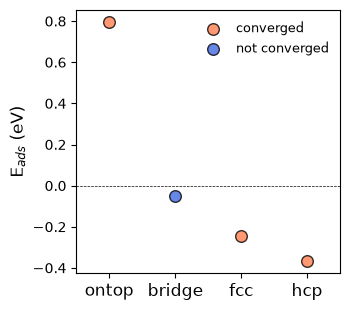

Spread between the highest and the lowest E_ads (eV)
1.164


In [12]:
positions = range(len(adsorption))
ok = adsorption["converged"].to_numpy()

fig, ax = plt.subplots(figsize=(3.6, 3.2))
ax.axhline(0, color="k", linestyle="--", linewidth=0.5)
ax.scatter([i for i in positions if ok[i]], adsorption["E_ads relaxed (eV)"][ok],
           s=70, facecolor="coral", edgecolor="black", alpha=0.8, label="converged")
ax.scatter([i for i in positions if not ok[i]], adsorption["E_ads relaxed (eV)"][~ok],
           s=70, facecolor="royalblue", edgecolor="black", alpha=0.8, label="not converged")
ax.set_xticks(list(positions))
ax.set_xticklabels(adsorption["site"], fontsize=12)
ax.set_xlim(-0.5, len(adsorption) - 0.5)
ax.set_ylabel("E$_{ads}$ (eV)", fontsize=12)
ax.legend(frameon=False, fontsize=9)

fig.tight_layout()
plt.show()

print("Spread between the highest and the lowest E_ads (eV)")
print(round(float(adsorption["E_ads relaxed (eV)"].max()
                  - adsorption["E_ads relaxed (eV)"].min()), 3))

## 8. What to report

- A relaxed energy can be reported only together with the settings that produced it, and the list is short
    - The model, and the head when the model has more than one: `mace` (MACE-MP-0) here, canon `C1`
    - The force target: `--fmax 0.05` eV/Å, canon `C2`
    - The optimizer and the step ceiling: `bfgs` and `--max-steps 200`
    - The steps taken and the `converged` label, per structure, canon `K1`
    - The reference the energy is measured against: ½ E(O2) here, relaxed at the same settings
    - That every term of the difference used those same settings, canon `C4`
    - The geometry the run ended on, checked against the site name on its folder, as the section on the site `bfgs` could not finish showed
- All of it is already on disk, so none of it is a memory and none of it is a guess
    - `mliprun_run.json` holds the settings, the package versions, the device, the timing and the outcome of every run
    - `opt_params.txt` holds the settings in a form you can read without a script
    - The cell below prints the provenance block of one of those records, which is where the version numbers in a methods section come from
- A sentence with all of it in it, for the relaxed `fcc` row of the table above:
    - "O on Pt(1 1 1), a 3 by 3 three-layer slab with the bottom layer fixed and 10 Å of vacuum, relaxed with MACE-MP-0 through mliprun to fmax 0.05 eV/Å with BFGS (16 steps, converged), gives E_ads = −0.24 eV against ½ E(O2) relaxed at the same settings."
- What that sentence does not say, on purpose
    - That −0.24 eV is the adsorption energy of O on Pt(1 1 1): it is this model's number at these settings, and the claim would need a DFT calculation at the level of theory the project records
    - Which of the two hollows is preferred, because the two are 0.125 eV apart and nothing in this notebook has checked that gap against anything

In [13]:
provenance = json.loads((sites_dir / "fcc" / "mliprun_run.json").read_text())["provenance"]

print("Model the run used")
print(provenance["mlip_model"])
print("Package behind that model, and its version")
print([provenance["mlip_package"]["name"], provenance["mlip_package"]["version"]])
print("mliprun version")
print(provenance["mliprun_version"])
print("ASE version")
print(provenance["ase_version"])
print("Device asked for, and the device used")
print([provenance["device_requested"], provenance["device_resolved"]])

parameters = json.loads((sites_dir / "fcc" / "mliprun_run.json").read_text())["parameters"]

print()
print("Settings the record kept, with where each value came from")
print(pd.DataFrame([{"setting": name,
                     "value": entry["value"],
                     "came from": entry["source"]}
                    for name, entry in parameters.items()
                    if name in ("optimizer", "fmax", "max_steps", "relax_cell")]
                   ).to_string(index=False))

Model the run used
mace
Package behind that model, and its version
['mace-torch', '0.3.16']
mliprun version
0.4.0
ASE version
3.29.0
Device asked for, and the device used
['cpu', 'cpu']

Settings the record kept, with where each value came from
   setting value came from
 optimizer  bfgs      user
      fmax  0.05      user
 max_steps   200      user
relax_cell False   default


## Check yourself

1. A colleague sends you a relaxed adsorption energy for O on a metal surface, and the folder the number came from.
   Which two files do you open first, and what are the five things you check in them before using the number?
2. Your relaxation of a bridge site stops after 200 steps with `converged` false, having taken its `E_ads` 0.505 eV
   down on the way. A labmate suggests raising `--max-steps` to 2000 and reporting that energy as the bridge
   adsorption energy. What is wrong with the plan, and what did this notebook's own run of that structure show?
3. You relax the four sites to `--fmax 0.05` and, to save time, take `E(slab)` from an older folder whose clean slab
   was relaxed to `--fmax 0.2`. Which canon item does that break, what does it do to the four `E_ads` values, and
   what does it do to the ranking between them?

<details>
<summary>Answers</summary>

- `mliprun_run.json` and `opt_params.txt`, the two files that record what was actually run. In them: the `converged`
  label, which lives in the last stage's `results` and not at the top level; the `fmax` target, because a number
  relaxed to 0.2 eV/Å is not comparable with one relaxed to 0.05; the optimizer and the number of steps, so you can
  see whether the run ended at its target or at its ceiling; the model and the head, canon `C1`, because a term from
  another model carries another energy zero, which is canon `C3`; and the reference the difference was taken against,
  with the settings it was relaxed at, canon `C4`. Then open `opt_final.vasp` and check the geometry against the site
  name on the folder, because a relaxed adsorbate does not have to still be where it was put
- More steps do not turn a saddle into a minimum. `bridge` is the point halfway between two surface atoms and the
  energy falls away from it sideways, so the O slides towards a hollow instead of settling, and there is no small
  force for the optimizer to find on the way. This notebook relaxed that same file with `--optimizer fire`: it
  converged in 67 steps, the O had slid 0.735 Å, it had three Pt neighbours instead of two, and it sat 0.065 Å in the
  plane from where the `fcc` run had put its own O, at an energy 0.003 eV from that run's. So the converged number is
  an `fcc` number, and reporting it as `bridge` would put the wrong site name on a real result. That is canon `A1`,
  which sites are studied at all, and canon `K1`, that `converged` is a label to read
- It breaks canon `C4`, one target for every term of one energy difference. The clean slab stopped higher in energy
  than a 0.05 eV/Å run would have left it, and it enters `E_ads` with a minus sign, so every one of the four `E_ads`
  comes out more negative than it should. The shift is the same on all four, so the ranking between the sites
  survives, and that is exactly the trap: the part you look at is fine while no single value is reportable. This
  notebook measured that term moving 0.253 eV between the slab as built and the slab at 0.05 eV/Å, so it is large
  enough to matter. Relax the clean slab again at 0.05 eV/Å, or relax everything at 0.2 eV/Å, so that one target
  covers every term of the formula

</details>